### Make a temporary space in /flash

In [1]:
import os, random, string

In [2]:
cwd = os.path.basename(os.getcwd())
tmpdir = os.path.join("/flash/ReiterU/tmp/", 'tomo_' + ''.join(random.choices(string.ascii_uppercase, k=12)))
print(tmpdir)
if not os.path.exists(tmpdir):
    os.makedirs(tmpdir)
    os.makedirs(os.path.join(tmpdir, "chirp"))

/flash/ReiterU/tmp/tomo_XOZLBEYSGIZW


## Preparations

### Import stuff

In [3]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
from scipy import signal
import h5py
import cv2
from scipy import ndimage as ndi
from roifile import roiread
import scipy.spatial.distance as dist
import scipy.cluster.hierarchy as sch
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
import matplotlib.patches as mpatches
from sklearn.decomposition import SparsePCA
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score

import scanpy as sc
from anndata import AnnData
import leidenalg
import igraph as ig

In [4]:
import sys
sys.path.append("../../")
from calfuncs.io import read_sync_ttl
from calfuncs.full_field_step import plot_chirp_eta, compute_qi

sys.path.append("./")
from plot_functions import characterize_neurons, plot_index, plot_cluster_average, plot_clustering, plot_spca_features

In [5]:
from matplotlib import font_manager
import matplotlib as mpl
font_manager.fontManager.addfont('/bucket/ReiterU/common/fonts/arial.ttf')
mpl.rcParams.update({
    'font.size': 7,
    'axes.titlesize': 7,
    'legend.fontsize': 7,
    'font.family': 'sans-serif',
    'font.sans-serif': "Arial",
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'axes.linewidth': 0.5,
    'xtick.major.width': 0.5,
    'xtick.major.size': 2,
    'xtick.minor.size': 2,
    'xtick.minor.width': 0.5,
    'ytick.major.width': 0.5,
    'ytick.minor.width': 0.5,
    'ytick.major.size': 2,
    'ytick.minor.size': 2,
})

In [6]:
database = [
    {
        "name": "20250110_rec2",
        "region": "OGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/20250110_rec2/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20250110_squid_cal520/2P/rec2/ROI_yutaka_renamed.zip",
        "depth_map": "/bucket/ReiterU/OLdev/experiments/20250110_squid_cal520/2P/rec2/cell_depths.csv",
        "template_img": "/bucket/ReiterU/OLdev/experiments/20250110_squid_cal520/2P/rec2/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
    {
        "name": "20250110_rec4",
        "region": "OGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/20250110_rec4/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20250110_squid_cal520/2P/rec4/ROI_yutaka_renamed.zip",
        "depth_map": "/bucket/ReiterU/OLdev/experiments/20250110_squid_cal520/2P/rec4/cell_depths.csv",
        "template_img": "/bucket/ReiterU/OLdev/experiments/20250110_squid_cal520/2P/rec4/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
    {
        "name": "20250110_rec11",
        "region": "OGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/20250110_rec11/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20250110_squid_cal520/2P/rec11/ROI_yutaka_renamed.zip",
        "depth_map": None,
        "template_img": "/bucket/ReiterU/OLdev/experiments/20250110_squid_cal520/2P/rec11/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
    {
        "name": "20250121_rec8",
        "region": "OGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/20250121_rec8/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20250121_squid_cal520/2P/rec8/ROI_yutaka_renamed.zip",
        "depth_map": None,
        "template_img": "/bucket/ReiterU/OLdev/experiments/20250121_squid_cal520/2P/rec8/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
    {
        "name": "20250212_rec5",
        "region": "OGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/20250212_rec5/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20250212_squid_cal520/2P/rec5/ROI_transformed_corrected_renamed.zip",
        "depth_map": "/bucket/ReiterU/OLdev/experiments/20250212_squid_cal520/2P/rec5/cell_depths.csv",
        "template_img": "/bucket/ReiterU/OLdev/experiments/20250212_squid_cal520/2P/rec5/run1/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
    {
        "name": "20250318_rec9",
        "region": "OGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/20250318_rec9/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20250318_squid_cal520/2P/rec9/ROI_yutaka_renamed.zip",
        "depth_map": "/bucket/ReiterU/OLdev/experiments/20250318_squid_cal520/2P/rec9/cell_depths.csv",
        "template_img": "/bucket/ReiterU/OLdev/experiments/20250318_squid_cal520/2P/rec9/run1/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
    {
        "name": "20250318_rec11",
        "region": "OGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/20250318_rec11/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20250318_squid_cal520/2P/rec11/ROI_yutaka_renamed.zip",
        "depth_map": "/bucket/ReiterU/OLdev/experiments/20250318_squid_cal520/2P/rec11/cell_depths.csv",
        "template_img": "/bucket/ReiterU/OLdev/experiments/20250318_squid_cal520/2P/rec11/run1/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
    {
        "name": "20250521_rec9",
        "region": "OGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/20250521_rec9/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20250521_squid_cal520/2P/rec9/ROI_yutaka_renamed.zip",
        "depth_map": None,
        "template_img": "/bucket/ReiterU/OLdev/experiments/20250521_squid_cal520/2P/rec9/run1/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
        {
        "name": "20241224_rec3",
        "region": "IGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/20241224_rec3/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20241224_squid_cal520/2P/rec3/ROI_yutaka_renamed.zip",
        "depth_map": "/bucket/ReiterU/OLdev/experiments/20241224_squid_cal520/2P/rec3/cell_depths.csv",
        "template_img": "/bucket/ReiterU/OLdev/experiments/20241224_squid_cal520/2P/rec3/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
    {
        "name": "20241224_rec4",
        "region": "IGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/20241224_rec4/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20241224_squid_cal520/2P/rec4/ROI_yutaka_renamed.zip",
        "depth_map": "/bucket/ReiterU/OLdev/experiments/20241224_squid_cal520/2P/rec4/cell_depths.csv",
        "template_img": "/bucket/ReiterU/OLdev/experiments/20241224_squid_cal520/2P/rec4/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
    {
        "name": "20250106_rec2",
        "region": "IGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/20250106_rec2/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20250106_squid_cal520/2P/rec2/ROI_yutaka_renamed.zip",
        "depth_map": None,
        "template_img": "/bucket/ReiterU/OLdev/experiments/20250106_squid_cal520/2P/rec2/run2/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
    {
        "name": "20250106_rec4",
        "region": "IGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/20250106_rec4/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20250106_squid_cal520/2P/rec4/ROI_yutaka_renamed.zip",
        "depth_map": None,
        "template_img": "/bucket/ReiterU/OLdev/experiments/20250106_squid_cal520/2P/rec4/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
    {
        "name": "20250110_rec5",
        "region": "IGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/20250110_rec5/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20250110_squid_cal520/2P/rec5/ROI_yutaka_renamed.zip",
        "depth_map": "/bucket/ReiterU/OLdev/experiments/20250110_squid_cal520/2P/rec5/cell_depths.csv",
        "template_img": "/bucket/ReiterU/OLdev/experiments/20250110_squid_cal520/2P/rec5/run2/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
    {
        "name": "20250110_rec7",
        "region": "IGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/20250110_rec7/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20250110_squid_cal520/2P/rec7/ROI_yutaka_renamed.zip",
        "depth_map": "/bucket/ReiterU/OLdev/experiments/20250110_squid_cal520/2P/rec7/cell_depths.csv",
        "template_img": "/bucket/ReiterU/OLdev/experiments/20250110_squid_cal520/2P/rec7/run2/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
    {
        "name": "20259117_rec8",
        "region": "IGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/20250117_rec8/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20250117_squid_cal520/2P/rec8/ROI_yutaka_renamed.zip",
        "depth_map": None,
        "template_img": "/bucket/ReiterU/OLdev/experiments/20250117_squid_cal520/2P/rec8/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
    {
        "name": "20250212_rec2",
        "region": "IGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/20250212_rec2/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20250212_squid_cal520/2P/rec2/ROI_yutaka_renamed.zip",
        "depth_map": "/bucket/ReiterU/OLdev/experiments/20250212_squid_cal520/2P/rec2/cell_depths.csv",
        "template_img": "/bucket/ReiterU/OLdev/experiments/20250212_squid_cal520/2P/rec2/run2/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
    {
        "name": "20250520_rec5",
        "region": "IGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/20250520_rec5/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20250520_squid_cal520/2P/rec5/ROI_van_renamed.zip",
        "depth_map": None,
        "template_img": "/bucket/ReiterU/OLdev/experiments/20250520_squid_cal520/2P/rec5/run2/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
    {
        "name": "20250520_rec9",
        "region": "IGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/20250520_rec9/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20250520_squid_cal520/2P/rec9/ROI_yutaka_renamed.zip",
        "depth_map": None,
        "template_img": "/bucket/ReiterU/OLdev/experiments/20250520_squid_cal520/2P/rec9/run2/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
    {
        "name": "20250521_rec4",
        "region": "IGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/20250521_rec4/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20250521_squid_cal520/2P/rec4/ROI_yutaka_renamed.zip",
        "depth_map": None,
        "template_img": "/bucket/ReiterU/OLdev/experiments/20250521_squid_cal520/2P/rec4/run2/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
    {
        "name": "20250522_rec3",
        "region": "IGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/20250522_rec3/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20250522_squid_cal520/2P/rec3/ROI_yutaka_renamed.zip",
        "depth_map": None,
        "template_img": "/bucket/ReiterU/OLdev/experiments/20250522_squid_cal520/2P/rec3/run2/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
    {
        "name": "20250522_rec6",
        "region": "IGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/20250522_rec6/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20250522_squid_cal520/2P/rec6/ROI_yutaka_renamed.zip",
        "depth_map": None,
        "template_img": "/bucket/ReiterU/OLdev/experiments/20250522_squid_cal520/2P/rec6/run2/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
]

### load data

In [7]:
with pd.HDFStore("/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/leiden/result_combined.hdf5", mode='r') as store:
    R = store["R"]
    E = store["E"]

In [8]:
R_raw = R.copy()

In [9]:
display(R)

,recording,region,neuron,good,time_0,time_1,time_2,time_3,time_4,time_5,...,spca_20,spca_21,spca_22,spca_23,spca_24,spca_25,spca_26,spca_27,spca_28,spca_29
0,0,OGL,0,True,-0.508928,-0.464390,-0.466365,-0.342068,-0.295410,-0.459671,...,-3.923330,3.709491,-4.282827,-0.105844,2.921576,-2.371190,6.794475,1.638139,-1.561589,-2.704803
1,0,OGL,1,True,-0.257964,-0.253338,-0.456095,-0.514363,-0.351929,-0.346033,...,5.339304,-1.933449,1.602021,-1.236076,-1.521483,-0.380997,-4.370857,0.172448,1.170956,2.915614
2,0,OGL,2,True,-0.602118,-0.612503,-0.581508,-0.606921,-0.662248,-0.678898,...,-3.798328,-3.903314,-4.688595,2.911292,4.142401,2.702043,13.248385,-2.709772,-9.203449,-3.090206
3,0,OGL,3,True,0.563219,0.600015,0.847742,0.828184,0.842527,0.744541,...,9.482357,-2.478874,0.828057,-1.545227,-1.273875,-0.399481,-8.381687,-0.387511,2.143006,4.293992
4,0,OGL,4,True,0.572637,0.440795,0.267777,0.706606,0.556995,0.539196,...,-3.026185,0.599556,-1.176504,1.177105,-0.400154,-0.211736,6.968509,-0.774289,-3.296001,-1.535753
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2994,20,IGL,187,True,0.576814,0.268578,0.004038,0.212486,0.774889,0.519236,...,-0.940315,1.341109,-1.425903,-1.533258,1.292770,0.239178,-1.165633,-0.675126,2.866180,0.216316
2995,20,IGL,188,False,0.203239,0.787004,0.771219,0.418283,0.112171,-0.219562,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2996,20,IGL,189,False,0.226999,0.060144,0.330831,0.602990,0.920282,0.464031,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2997,20,IGL,190,True,-0.093924,-0.147579,-0.555467,-0.544272,-0.422625,-0.378776,...,-5.141545,-0.621915,10.703491,-2.334290,-0.142033,1.796851,1.115120,0.315398,-7.363258,-0.230249


In [10]:
display(E)

y
recording neuron session trial time            
0         0      0       0     -2000        NaN
                               -1950        NaN
                               -1900        NaN
                               -1850        NaN
                               -1800        NaN
...                                         ...
20        191    2       9      18750 -1.157461
                                18800 -2.285858
                                18850 -1.617408
                                18900 -0.432541
                                18950  0.188074

[45148320 rows x 1 columns]

### Reorder cluster IDs

In [11]:
def reassign_cluster_ids(df):
    """
    Re-assign cluster IDs based on similarity
    """
    d = df[df["good"]].copy()
    # X = d.filter(regex="^time_").to_numpy()
    X = d.filter(regex="^spca_").to_numpy()
    cluster_ids = d["cluster"]
    cluster_id_list = np.unique(cluster_ids)
    cluster_means = np.array([X[cluster_ids == c].mean(axis=0) for c in cluster_id_list])
    distance_matrix = dist.pdist(cluster_means, metric="euclidean")
    Z = sch.linkage(distance_matrix, method="average")
    row_order = sch.leaves_list(Z)

    # re-assign cluster ID based on the similarity
    lut = {}
    for (i, j) in enumerate(row_order):
        lut[cluster_id_list[j]] = i
    lut[-1] = -1
    print(lut)

    df_out = df.copy()
    df_out['cluster'] = df_out['cluster'].replace(lut)

    return df_out

In [13]:
R = reassign_cluster_ids(R)
# make IDs start from 1
R.loc[(R["cluster"]>=0), "cluster"] += 1

{np.float64(8.0): 0, np.float64(2.0): 1, np.float64(17.0): 2, np.float64(18.0): 3, np.float64(3.0): 4, np.float64(4.0): 5, np.float64(7.0): 6, np.float64(5.0): 7, np.float64(13.0): 8, np.float64(9.0): 9, np.float64(12.0): 10, np.float64(6.0): 11, np.float64(14.0): 12, np.float64(1.0): 13, np.float64(19.0): 14, np.float64(20.0): 15, np.float64(0.0): 16, np.float64(10.0): 17, np.float64(11.0): 18, np.float64(22.0): 19, np.float64(21.0): 20, np.float64(15.0): 21, np.float64(16.0): 22, -1: -1}


In [15]:
display(R)

,recording,region,neuron,good,time_0,time_1,time_2,time_3,time_4,time_5,...,spca_20,spca_21,spca_22,spca_23,spca_24,spca_25,spca_26,spca_27,spca_28,spca_29
0,0,OGL,0,True,-0.508928,-0.464390,-0.466365,-0.342068,-0.295410,-0.459671,...,-3.923330,3.709491,-4.282827,-0.105844,2.921576,-2.371190,6.794475,1.638139,-1.561589,-2.704803
1,0,OGL,1,True,-0.257964,-0.253338,-0.456095,-0.514363,-0.351929,-0.346033,...,5.339304,-1.933449,1.602021,-1.236076,-1.521483,-0.380997,-4.370857,0.172448,1.170956,2.915614
2,0,OGL,2,True,-0.602118,-0.612503,-0.581508,-0.606921,-0.662248,-0.678898,...,-3.798328,-3.903314,-4.688595,2.911292,4.142401,2.702043,13.248385,-2.709772,-9.203449,-3.090206
3,0,OGL,3,True,0.563219,0.600015,0.847742,0.828184,0.842527,0.744541,...,9.482357,-2.478874,0.828057,-1.545227,-1.273875,-0.399481,-8.381687,-0.387511,2.143006,4.293992
4,0,OGL,4,True,0.572637,0.440795,0.267777,0.706606,0.556995,0.539196,...,-3.026185,0.599556,-1.176504,1.177105,-0.400154,-0.211736,6.968509,-0.774289,-3.296001,-1.535753
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2994,20,IGL,187,True,0.576814,0.268578,0.004038,0.212486,0.774889,0.519236,...,-0.940315,1.341109,-1.425903,-1.533258,1.292770,0.239178,-1.165633,-0.675126,2.866180,0.216316
2995,20,IGL,188,False,0.203239,0.787004,0.771219,0.418283,0.112171,-0.219562,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2996,20,IGL,189,False,0.226999,0.060144,0.330831,0.602990,0.920282,0.464031,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2997,20,IGL,190,True,-0.093924,-0.147579,-0.555467,-0.544272,-0.422625,-0.378776,...,-5.141545,-0.621915,10.703491,-2.334290,-0.142033,1.796851,1.115120,0.315398,-7.363258,-0.230249


### Plot results

In [16]:
R2 = R[R["good"]].copy()
R2.reset_index(inplace=True)
characterize_neurons(R2, E)

In [ ]:
t = np.arange(21000) * 1e-3
stimulus = np.zeros_like(t)
stimulus[0:2000] = 0
stimulus[2000:6000] = 1
stimulus[6000:10000] = 0
stimulus[10000:12000] = 0.5
stimulus[12000:20000] = 0.5 + 0.5 * signal.chirp(np.linspace(0, 8, 8000), f0=0.5, f1=10, t1=8, method='logarithmic', phi=90)
stimulus[20000:21000] = 0

cluster_ids = R2["cluster"].sort_values().unique()

alphabet_colors = [
    "#F0A0FF", "#0075DC", "#993F00", "#4C005C", "#191919", "#005C31",
    "#2BCE48", "#FFCC99", "#808080", "#94FFB5", "#8F7C00", "#9DCC00",
    "#C20088", "#003380", "#FFA405", "#FFA8BB", "#426600", "#FF0010",
    "#5EF1F2", "#00998F", "#E0FF66", "#740AFF", "#990000", "#FFFF80",
    "#FFE100", "#FF5005"
]
alphabet_cmap = mpl.colors.ListedColormap(alphabet_colors, name='alphabet')
color_map = {i: alphabet_cmap(i-1) for i in np.unique(cluster_ids).astype("int")}

with mpl.rc_context(rc={'font.size': 6, 'axes.titlesize': 6, 'legend.fontsize': 6}):
    plot_clustering(R2, color_map, stimulus, vmin=-1.0, vmax=2.2, colormap_name="bone_r", figsize=(3.0,4.0))
    plot_cluster_average(R2, color_map, stimulus, ymin=-1.5, ymax=2.5, figsize=(3.4,4.0))
    plot_index(R2, color_map, figsize=(1.5,4.0))

In [ ]:
R3 = R[(R["good"]) & (R["cluster"].isin([21,22,23]))].copy()
# R3["cluster"] = 1

plot_clustering(R3, color_map, stimulus, vmin=-1.0, vmax=2.2, colormap_name="bone_r", sort_within_cluster=True, figsize=(3.0,4.0))
plot_spca_features(R3, color_map, vmin=-10, vmax=10, colormap_name="viridis", sort_within_cluster=True, figsize=(3.0,2.0))

### Manually merge clusters

In [19]:
lut = {
    -1: -1,
    1: 1,
    2: 2,
    3: -1,
    4: 3,
    5: 4,
    6: 4,
    7: 4,
    8: 5,
    9: 5,
    10: 6,
    11: -1,
    12: 8,
    13: 8,
    14: 9,
    15: 9,
    16: 10,
    17: 11,
    18: 12,
    19: 13,
    20: 14,
    21: 15,
    22: 15,
    23: 15
}

R['cluster'] = R['cluster'].replace(lut)
R.loc[R['cluster'] == -1, "good"] = False

In [20]:
R = reassign_cluster_ids(R)
# make IDs start from 1
R.loc[(R["cluster"]>=0), "cluster"] += 1

{np.float64(5.0): 0, np.float64(6.0): 1, np.float64(2.0): 2, np.float64(1.0): 3, np.float64(3.0): 4, np.float64(4.0): 5, np.float64(10.0): 6, np.float64(11.0): 7, np.float64(12.0): 8, np.float64(8.0): 9, np.float64(9.0): 10, np.float64(15.0): 11, np.float64(13.0): 12, np.float64(14.0): 13, -1: -1}


In [21]:
R3 = R[(R["good"])].copy()
R3.reset_index(inplace=True)
characterize_neurons(R3, E)

In [ ]:
t = np.arange(21000) * 1e-3
stimulus = np.zeros_like(t)
stimulus[0:2000] = 0
stimulus[2000:6000] = 1
stimulus[6000:10000] = 0
stimulus[10000:12000] = 0.5
stimulus[12000:20000] = 0.5 + 0.5 * signal.chirp(np.linspace(0, 8, 8000), f0=0.5, f1=10, t1=8, method='logarithmic', phi=90)
stimulus[20000:21000] = 0

cluster_ids = R3["cluster"].sort_values().unique()

alphabet_colors = [
    "#F0A0FF", "#0075DC", "#993F00", "#4C005C",
    "#2BCE48", "#94FFB5", "#FFCC99", "#9DCC00",
    "#C20088", "#003380", "#FFA405", "#8F7C00", 
    "#5EF1F2", "#00998F", "#E0FF66", "#740AFF", "#990000", "#FFFF80",
    "#FFE100", "#FF5005", "#808080"
]
alphabet_cmap = mpl.colors.ListedColormap(alphabet_colors, name='alphabet')
color_map = {i: alphabet_cmap(i-1) for i in np.unique(cluster_ids).astype("int")}

with mpl.rc_context(rc={'font.size': 6, 'axes.titlesize': 6, 'legend.fontsize': 6}):
    plot_clustering(R3, color_map, stimulus, vmin=-1.0, vmax=2.2, colormap_name="bone_r", figsize=(3.0,4.0),)
    plot_clustering(R3, color_map, stimulus, vmin=-1.0, vmax=2.2, colormap_name="bone_r", sort_within_cluster=True, figsize=(3.0,4.0))
    plot_cluster_average(R3, color_map, stimulus, ymin=-1.5, ymax=2.5, figsize=(3.4,4.0))
    plot_index(R3, color_map, figsize=(1.5,4.0))

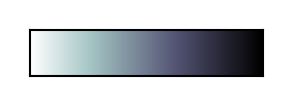

In [23]:
gradient = np.linspace(0, 1, 256).reshape(1, -1)
gradient = np.vstack([gradient] * 20)

fig, ax = plt.subplots(figsize=(1, 0.2), dpi=300)
ax.imshow(gradient, aspect='auto', cmap='bone_r')
# ax.set_axis_off()
ax.set_xticks([])
ax.set_yticks([])
plt.savefig(os.path.join(tmpdir, "bone_r_colormap.pdf"))
plt.show()

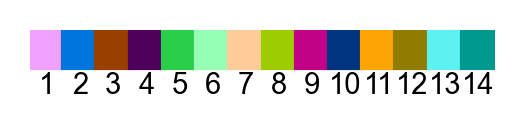

In [24]:
fig, ax = plt.subplots(figsize=(2, 0.2), dpi=300)
for i in range(1, len(color_map)+1):  # cmap.N is the number of colors in tab10 (10)
    ax.add_patch(plt.Rectangle((i, 0), 1, 1, color=color_map[i]))
    ax.text(i + 0.5, -0.1, str(i), ha="center", va="top")
ax.set_xlim(1, len(color_map)+1)
ax.set_ylim(-0.2, 1)
ax.axis("off")
plt.savefig(os.path.join(tmpdir, "cluster_colormap.pdf"))
plt.show()

### UMAP visualization

2025-06-06 23:16:40.385768: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1749219400.401635 1056840 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1749219400.406382 1056840 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1749219400.419261 1056840 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1749219400.419272 1056840 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1749219400.419274 1056840 computation_placer.cc:177] computation placer alr

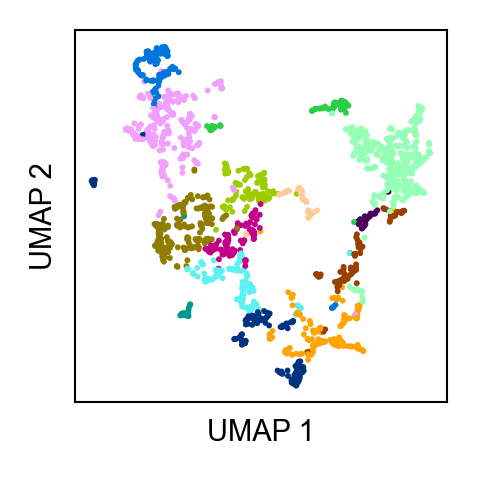

In [25]:
S = R3.filter(regex="^spca_").to_numpy()
adata = AnnData(S)
adata.obsm['X_spca'] = S

sc.pp.neighbors(adata, n_neighbors=5, metric='cosine', use_rep='X_spca', random_state=2025)
sc.tl.umap(adata, n_components=2, min_dist=0.05, spread=3.0)

fig, ax = plt.subplots(figsize=(1.6,1.6), dpi=300)
um = adata.obsm['X_umap']
point_colors = [color_map[e] for e in R3["cluster"]]
scatter = ax.scatter(um[:, 0], um[:, 1], c=point_colors, s=2, alpha=1, lw=0)
ax.set_xlabel("UMAP 1")
ax.set_ylabel("UMAP 2")
ax.set_xticks([])
ax.set_yticks([])
ax.yaxis.set_inverted(True)
ax.xaxis.set_inverted(True)
plt.tight_layout()
# plt.savefig(os.path.join(tmpdir, "umap.pdf"), bbox_inches='tight')
plt.show()

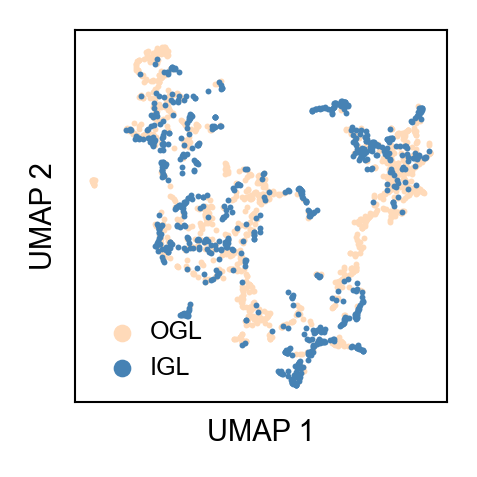

In [26]:
fig, ax = plt.subplots(figsize=(1.6,1.6), dpi=300)

um = adata.obsm['X_umap']
ogl_idx = R3[R3["region"] == "OGL"].index
igl_idx = R3[R3["region"] == "IGL"].index

ax.scatter(um[ogl_idx, 0], um[ogl_idx, 1], color='peachpuff', s=2, alpha=1, lw=0, label="OGL")
ax.scatter(um[igl_idx, 0], um[igl_idx, 1], color='steelblue', s=2, alpha=1, lw=0, label="IGL")
ax.set_xlabel("UMAP 1")
ax.set_ylabel("UMAP 2")
ax.set_xticks([])
ax.set_yticks([])
ax.yaxis.set_inverted(True)
ax.xaxis.set_inverted(True)
ax.legend(frameon=False, loc="lower left", markerscale=3, fontsize=6, handletextpad=0.1)
plt.tight_layout()
# plt.savefig(os.path.join(tmpdir, "umap_region.pdf"), bbox_inches='tight')
plt.show()

Number of OGL neurons: 1085
Number of IGL neurons: 762


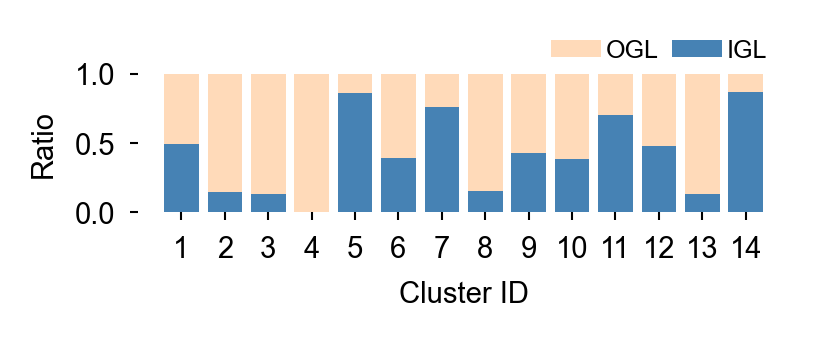

In [27]:
df1 = R3[R3["region"] == "OGL"]
df2 = R3[R3["region"] == "IGL"]
print("Number of OGL neurons:", df1.shape[0])
print("Number of IGL neurons:", df2.shape[0])

c1, c2 = [], []
for i in range(1, int(R3["cluster"].max())+1):
    c1.append(df1[df1["cluster"] == i].shape[0])
    c2.append(df2[df2["cluster"] == i].shape[0])
c1 = np.array(c1)
c2 = np.array(c2)

r1 = c1 / (c1 + c2)
r2 = c2 / (c1 + c2)
x = np.arange(1, r1.size + 1)

fig, ax = plt.subplots(figsize=(2.8,0.6), dpi=300)
ax.bar(x, r1, bottom=r2, width=0.8, color="peachpuff", label="OGL")
ax.bar(x, r2, width=0.8, color="steelblue", label="IGL")
ax.set_xlim(0, r1.size+1)
ax.set_ylim(0,1)
ax.set_xlabel("Cluster ID")
ax.set_ylabel("Ratio")
ax.set_xticks(np.arange(1, R3["cluster"].max()+1))
# ax.xaxis.set_tick_params(labelsize=6)
ax.legend(frameon=False, bbox_to_anchor=(0.6, 0.92), ncol=2, columnspacing=0.5, markerscale=1,  handletextpad=0.2, fontsize=6)
for sp in ["top", "right", "bottom", "left"]:
    ax.spines[sp].set_visible(False)

plt.savefig(os.path.join(tmpdir, "cluster_ratios.pdf"), bbox_inches='tight')
plt.show()

### Save dataframe

In [28]:
with pd.HDFStore(os.path.join(tmpdir, "result_combined_merged.hdf5"), mode='w') as store:
    store.put('R', R)
    store.put('E', E)

### Copy data to bucket

In [29]:
savedir = "/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/leiden_merged"
print(f"mkdir -p {savedir}")
print(f"cp -r {tmpdir}/* {savedir}")

mkdir -p /bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/leiden_merged
cp -r /flash/ReiterU/tmp/tomo_ECBOJSLJTMPL/* /bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/leiden_merged
